# Rabbits and foxes, with `solve_ivp`

**CHME 5137, Lecture 8, Tuesday October 6, 2026.** Started in class, finished for
homework.

*Revised for 2026 by Claude Code (Claude Opus 5.5) from the Lecture 3 notebook, and
checked by Prof. West. The problem is from Chapter 1 of H. Scott Fogler's
"Essentials of Chemical Reaction Engineering". The tasks are new.*

---

There are initially 400 rabbits and 200 foxes on a farm. (Or two cell types in a
96-well plate, if you prefer.) The populations obey

$$\frac{dR}{dt} = k_1 R - k_2 R F \qquad\qquad \frac{dF}{dt} = k_3 R F - k_4 F$$

* Growth of rabbits, $k_1 = 0.015$ day$^{-1}$
* Death of rabbits being eaten by foxes, $k_2 = 0.00004$ day$^{-1}$ foxes$^{-1}$
* Growth of foxes after eating rabbits, $k_3 = 0.0004$ day$^{-1}$ rabbits$^{-1}$
* Death of foxes, $k_4 = 0.04$ day$^{-1}$

In Lecture 3 you solved this with Euler's method. You found that the fox peaks,
which should all be the same height, crept upwards. At a step of 0.1 days (12,000
steps for 1200 days) they went 2816, 2854, 2893. At 0.005 days (240,000 steps) they
went 2804.5, 2806.4, 2808.2. Today: how well does a library do, and at what cost?

### How to work

- **Commit as you go.** After each numbered task works, Restart & Run All, then
  stage, commit with a message that says what you did, and push. At least one commit
  per task. Your commit history is part of what gets looked at.
- **Answer the questions in words**, in the markdown cells marked *Answer*.
  Double-click a cell to edit it.
- **Use the in-class notebook**, `solve-ivp-intro.ipynb`, for the syntax.

In [121]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1 = 0.015  # 1/day
k2 = 0.00004  # 1/day/fox
k3 = 0.0004  # 1/day/rabbit
k4 = 0.04  # 1/day

y0 = [400.0, 200.0]  # [rabbits, foxes] at t = 0

## 1. Solve it, and plot it

Write a function `dydt(t, y)` that returns $[dR/dt,\ dF/dt]$. Then call
`solve_ivp` with its **default** settings for 600 days.

Print `sol.success`, `sol.nfev` and `len(sol.t)`. Then plot both populations
against time, with axis labels and a legend.

True The solver successfully reached the end of the integration interval.
shape of sol.y: (2, 32)
shape of sol.t: (32,)
function evaluations: 242
lenth of sol.t: 32


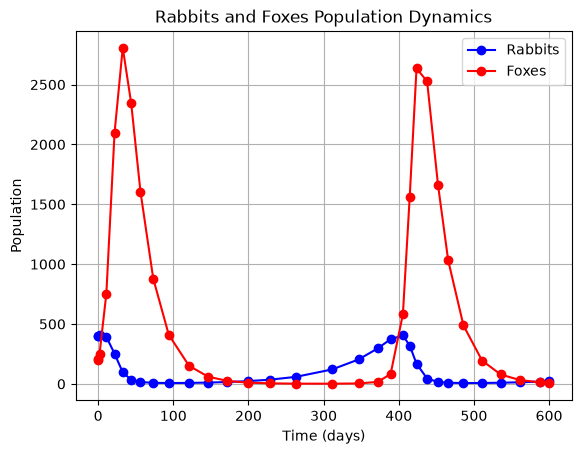

In [122]:
def dydt(t, y):
    R, F = y
    dRdt = k1 * R - k2 * R * F
    dFdt = k3 * R * F - k4 * F 
    return [dRdt, dFdt]

y0 = [400.0, 200.0]  # [rabbits, foxes] at t = 0
t_span = (0, 600)  # time span for the simulation

sol = solve_ivp(dydt, t_span, y0)


print(sol.success, sol.message)
print("shape of sol.y:", sol.y.shape)
print("shape of sol.t:", sol.t.shape)
print("function evaluations:", sol.nfev)
print("lenth of sol.t:", len(sol.t))


plt.plot(sol.t, sol.y[0], "o-", label="Rabbits", color="blue")
plt.plot(sol.t, sol.y[1], "o-", label="Foxes", color="red")
plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.title("Rabbits and Foxes Population Dynamics")
plt.legend()
plt.grid()
plt.show()


Your plot is probably jagged. Why? Fix it in two ways: with `t_eval`, and with
`dense_output=True`. Does either one change `sol.nfev`?

True The solver successfully reached the end of the integration interval.
shape of sol.y: (2, 100)
shape of sol.t: (100,)
function evaluations: (100,)
length of sol.t: 100


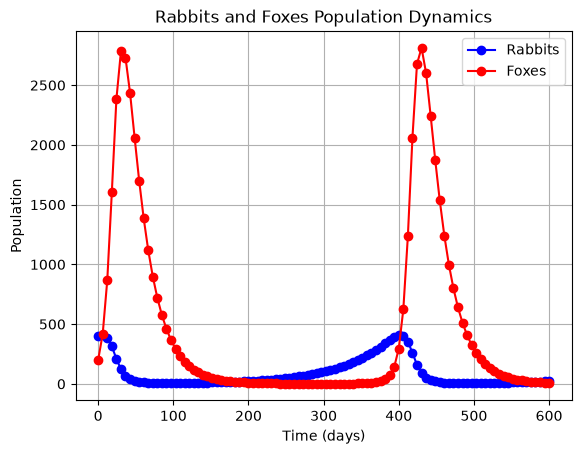

In [123]:
def dydt(t, y):
    R, F = y
    dRdt = k1 * R - k2 * R * F
    dFdt = k3 * R * F - k4 * F 
    return [dRdt, dFdt]

y0 = [400.0, 200.0]  # [rabbits, foxes] at t = 0
t_span = (0, 600)  # time span for the simulation
t_eval = np.linspace(0, 600, 100)  # exact solution at t=0
sol = solve_ivp(dydt, t_span, y0, t_eval=t_eval)


print(sol.success, sol.message)
print("shape of sol.y:", sol.y.shape)
print("shape of sol.t:", sol.t.shape)
print("function evaluations:", t_eval.shape)
print("length of sol.t:", len(sol.t))


#c_exact = np.array([400.0, 200.0])  # exact solution at t=0
plt.plot(sol.t, sol.y[0], "o-", label="Rabbits", color="blue")
plt.plot(sol.t, sol.y[1], "o-", label="Foxes", color="red")
plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.title("Rabbits and Foxes Population Dynamics")
plt.legend()
plt.grid()
plt.show()


True The solver successfully reached the end of the integration interval.
shape of sol_dense.y: (2, 32)
shape of sol_dense.t: (32,)
function evaluations: 242
length of sol_dense.t: 32


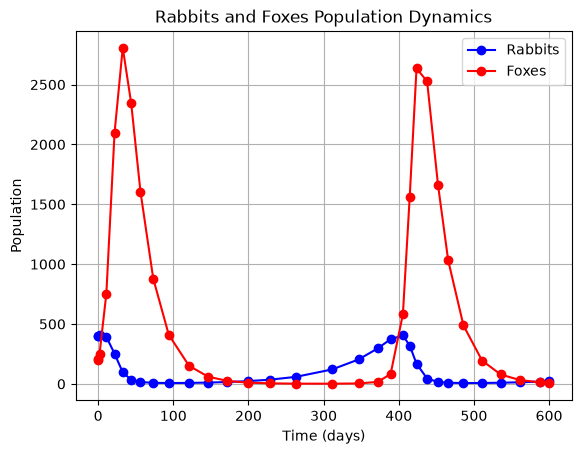

In [124]:
def dydt(t, y):
    R, F = y
    dRdt = k1 * R - k2 * R * F
    dFdt = k3 * R * F - k4 * F 
    return [dRdt, dFdt]

y0 = [400.0, 200.0]  # [rabbits, foxes] at t = 0
t_span = (0, 600)  # time span for the simulation
sol_dense = solve_ivp(dydt, t_span, y0, dense_output=True)


print(sol_dense.success, sol_dense.message)
print("shape of sol_dense.y:", sol_dense.y.shape)
print("shape of sol_dense.t:", sol_dense.t.shape)
print("function evaluations:", sol_dense.nfev)
print("length of sol_dense.t:", len(sol_dense.t))


#c_exact = np.array([400.0, 200.0])  # exact solution at t=0
plt.plot(sol_dense.t, sol_dense.y[0], "o-", label="Rabbits", color="blue")
plt.plot(sol_dense.t, sol_dense.y[1], "o-", label="Foxes", color="red")
plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.title("Rabbits and Foxes Population Dynamics")
plt.legend()
plt.grid()
plt.show()

*Answer:*

t_eval gives the steep curve when comapred to dense_output and nfev. The step size is less in t_eval fuction (i.e 100), this makes the grap smooth curve at peak points (Time: ~420, population: ~2600) whereas, other two solve functions step size is less so there is jagged curve. t_eval is more over like Adam_bashforth method. 

## 2. The phase portrait

Solve to 1200 days, three full cycles, and plot foxes against rabbits. The exact
solution is a closed loop, traced over and over. Is yours?

True The solver successfully reached the end of the integration interval.
shape of sol.y: (2, 56)
shape of sol.t: (56,)
function evaluations: 440
lenth of sol.t: 56


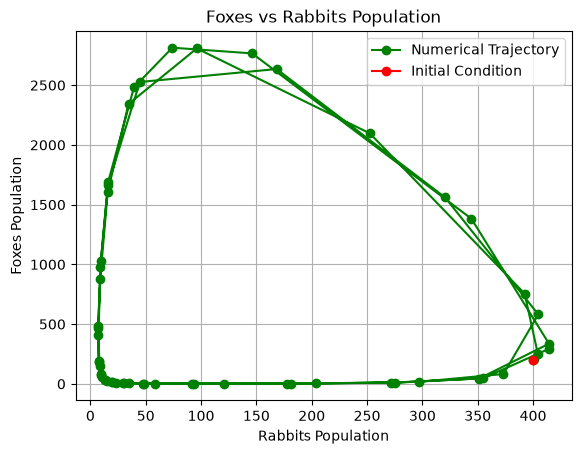

In [125]:
def dydt(t, y):
    R, F = y
    dRdt = k1 * R - k2 * R * F
    dFdt = k3 * R * F - k4 * F 
    return [dRdt, dFdt]

y0 = [400.0, 200.0]  # [rabbits, foxes] at t = 0
t_span = (0, 1200)  # time span for the simulation

sol = solve_ivp(dydt, t_span, y0)


print(sol.success, sol.message)
print("shape of sol.y:", sol.y.shape)
print("shape of sol.t:", sol.t.shape)
print("function evaluations:", sol.nfev)
print("lenth of sol.t:", len(sol.t))


plt.plot(sol.y[0], sol.y[1], "o-", label="Numerical Trajectory", color="green")
plt.plot(y0[0], y0[1], "o-", label="Initial Condition", color="red")
plt.xlabel("Rabbits Population")
plt.ylabel("Foxes Population")
plt.title("Foxes vs Rabbits Population")
plt.legend()
plt.grid()
plt.show()


*Answer:*

Over time 1200 days three full cycles, the relative tolerance and absolute tolarence are difficult to findout from the plot, in loop conditions to get the absolute zero error, each cycle must retract the same loop, but in this plot in each cycle spiral was either grows inward or shrinks outward that results non absoulte error. 

## 3. The height of each fox peak, using events

Searching `sol.y` for the largest value gives you the largest value **at the times
the solver happened to stop**, which won't be exactly at the peak. `solve_ivp` can
find the exact moment instead, with an *event*: a function `g(t, y)` that it
watches. It reports every time `g` passes through zero.

The foxes peak when $dF/dt$ changes from positive to negative. Since
$dF/dt = F(k_3 R - k_4)$ and $F > 0$, that happens when $k_3 R - k_4$ goes from
positive to negative. So:

```python
def fox_peak(t, y):
    R, F = y
    return k3 * R - k4

fox_peak.direction = -1   # only count it when g is decreasing through zero

sol = solve_ivp(dydt, (0, 1200), y0, events=fox_peak)
sol.t_events[0]          # the times of the peaks
sol.y_events[0]          # the [R, F] values at each one
```

Print the time and height of each fox peak, with the default tolerances. Compare
with the Euler peaks above. How many function evaluations did it take, compared
with Euler's 12,000 or 240,000 steps?

Number of fox population peaks: 3
 peak        times      Rabbits    Foxes
   1         32.32      100.00     2808.63
   2        429.10      100.00     2821.00
   3        828.52      100.00     2860.88
function evaluations: 440
solver steps: 56


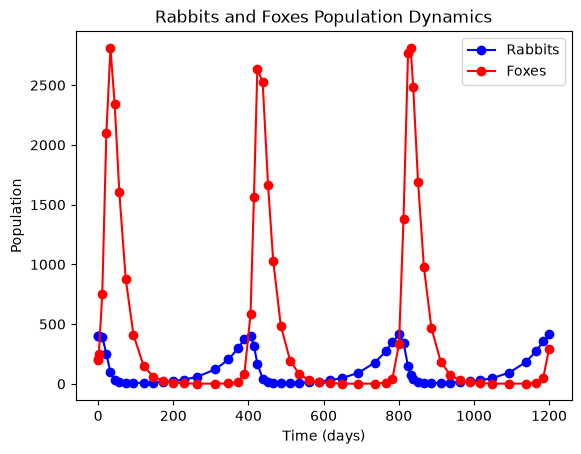

In [126]:
def dydt(t, y):
    R, F = y
    dRdt = k1 * R - k2 * R * F
    dFdt = k3 * R * F - k4 * F 
    return [dRdt, dFdt]

y0 = [400.0, 200.0]  # [rabbits, foxes] at t = 0
t_span = (0, 1200)  # time span for the simulation

def fox_peak(t, y):
    R, F = y
    return k3 * R - k4

fox_peak.direction = -1

sol = solve_ivp(dydt, t_span, y0, events=fox_peak)

sol.t_events[0]
sol.y_events[0]

print("Number of fox population peaks:", len(sol.t_events[0]))

print(" peak        times      Rabbits    Foxes")
for i, (tp, yp) in enumerate(zip(sol.t_events[0], sol.y_events[0]), start=1):
    print(f"{i:4d}    {tp:10.2f}    {yp[0]:8.2f}    {yp[1]:8.2f}")

print("function evaluations:", sol.nfev)
print("solver steps:", len(sol.t))

plt.plot(sol.t, sol.y[0], "o-", label="Rabbits", color="blue")
plt.plot(sol.t, sol.y[1], "o-", label="Foxes", color="red")
plt.xlabel("Time (days)")
plt.ylabel("Population")
plt.title("Rabbits and Foxes Population Dynamics")
plt.legend()
plt.show() 

*Answer:*

With sol.y, the number of fox population peaks are 3, function evalutions are 440 and it took 44 steps to reach 1200 days. Whereas, with euler method with step size of 0.1, the function evalutions are 12000 for 1200 days and the nuber of fox population peaks are 10. Similarly, for 24000 steps the function evealutions are 24000. 

## 4. Required accuracy: `rtol`

The true peaks are all the same height. So the *drift*, last peak minus first, is a
measure of the error, and we don't need the exact answer to find it.

Loop over `rtol` from `1e-3` to `1e-10`, keeping `atol = 1e-8`. For each value
record the drift and `sol.nfev`. Then make two log-log plots: |drift| against
`rtol`, and |drift| against `nfev`. The second is called a *work–precision
diagram*.

- How tight must `rtol` be for the peaks to agree to within one fox? To within
  0.01 of a fox?
- What is the height of the fox peak, to as many significant figures as you can
  justify? How do you know?
- Euler with 240,000 steps had a drift of 3.7 foxes. How many function evaluations
  does `solve_ivp` need to do better than that?

   rtol     first_peak    last_peak     drift         nfev
   1.0e-03  2808.625473  2860.819804 5.219433e+01      440
   1.0e-04  2804.082089  2805.681834 1.599745e+00      656
   1.0e-06  2803.866741  2803.877010 1.026863e-02     1424
   1.0e-08  2803.870129  2803.870091 -3.740569e-05     3152
   1.0e-10  2803.870096  2803.870095 -7.665817e-07     6254


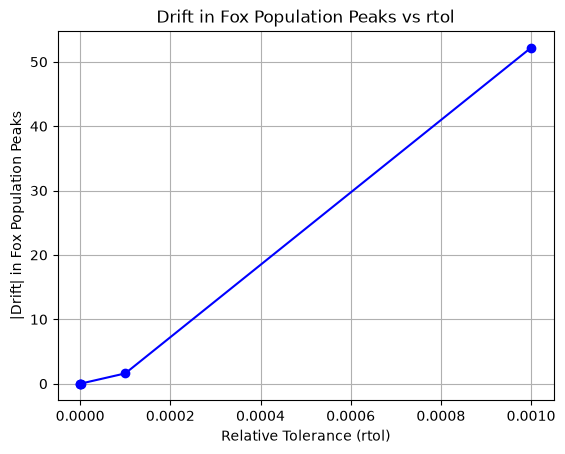

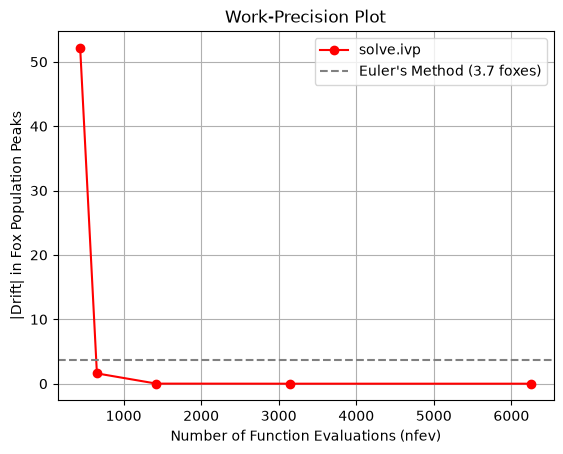

drift < 1.0: rtol = 1.0e-06, nfev = 1424
drift < 0.01: rtol = 1.0e-08, nfev = 3152
rtol = 1.0e-04   change in first peak = 4.54e+00
rtol = 1.0e-06   change in first peak = 2.15e-01
rtol = 1.0e-08   change in first peak = 3.39e-03
rtol = 1.0e-10   change in first peak = 3.24e-05
fox peak height: 2803.87009610723
smallest nfev with drift < 3.7: 656


In [127]:
t_span = (0, 1200) 
rtols = [1e-3, 1e-4, 1e-6, 1e-8, 1e-10]
drift = []
nfev = []
first_peak = []
last_peak = []


for rtol in rtols:
    sol = solve_ivp(dydt, t_span, y0, events=fox_peak, rtol=rtol, atol=1e-8)
    peaks = sol.y_events[0][:, 1]
    first_peak.append(peaks[0])
    last_peak.append(peaks[-1])
    drift.append(peaks[-1] - peaks[0])
    nfev.append(sol.nfev)

drift = np.array(drift)
nfev = np.array(nfev)
abs_drift = np.abs(drift)

print("   rtol     first_peak    last_peak     drift         nfev")
for rtol, first, last, d, n in zip(rtols, first_peak, last_peak, drift, nfev):
    print(f"{rtol:10.1e} {first:12f} {last:12f} {d:8e} {n:8d}")


# |drit| vs rtol plot
plt.plot(rtols, abs_drift, "o-", color="blue")
plt.xlabel("Relative Tolerance (rtol)")
plt.ylabel("|Drift| in Fox Population Peaks")
plt.title("Drift in Fox Population Peaks vs rtol")
plt.grid(True)
plt.show()

# work-precision plot

plt.plot(nfev, abs_drift, "o-", color="red", label="solve.ivp")
plt.axhline(3.7, color="gray", linestyle="--", label="Euler's Method (3.7 foxes)")
plt.xlabel("Number of Function Evaluations (nfev)")
plt.ylabel("|Drift| in Fox Population Peaks")
plt.title("Work-Precision Plot")
plt.legend()
plt.grid(True)
plt.show()

rtols = np.array(rtols)
for target in [1.0, 0.01]:
    ok = drift < target
    if np.any(ok):
        print(f"drift < {target}: rtol = {rtols[ok][0]:.1e}, nfev = {nfev[ok][0]}")
    else:
        print(f"No rtol achieved drift < {target}")

peak1 = np.array(first_peak)
for i in range(1, len(rtols)):
    print(f"rtol = {rtols[i]:.1e}   change in first peak = {abs(peak1[i] - peak1[i-1]):.2e}")
print("fox peak height:", peak1[-1])

ok = drift < 3.7
print("smallest nfev with drift < 3.7:", nfev[ok].min())

*Answer:*

The range of rtol is 1.0e-3 to 1.0e-10 for the tighten rtol, drift<1 within one fox and drift<0.01 with in 0.01 fox. the tight rtol for drift<1 is 1.0e-06 and for drift<0.01 rtol is 1.0e-08. 

The highest peak of fox is 2803.87. This is evaluated using absolute and relative tolerance. At each rtol, the change in peak height is evaluated, as the days increses the height of peak incresed and delta of peak is being decreased whihc means the foxes population is reaching the heighest. So, between rtol e-08 to e-10, fox peak reaches maximum value. 

As we observed in above question, solve_ivp required less number of function evalutions compared to euler. So, for drift<3.7 the number of function evalutions using solve_ivp are 656. 

## 5. `atol`, and how few foxes is too few?

What is the **smallest** number of foxes during the cycle, and of rabbits? (Use
`dense_output=True` and a fine grid of times, or another event.)

Now someone argues: "A fraction of a fox is meaningless, so I'll set `atol = 1`."
Try it, with `rtol = 1e-6`. Then try `atol = 10`. What happens to the peaks? Explain
why, using the formula for the error tolerance, $\text{atol} + \text{rtol}\,|y|$.

And about the model itself: what does a population of under two foxes mean? Would a
real population survive that trough? (Lecture 10, kinetic Monte Carlo, is one way
to model that properly.)

Minimum Rabbits: 7.43 at t = 887.25
Minimum Foxes: 1.59 at t = 297.63
atol = 1.0e-08,   fox peaks: 3, first peak: 2803.87, last peak: 2803.88, drift: 0.01, nfev: 1424
atol = 1.0e+00,   fox peaks: 4, first peak: 2804.05, last peak: 2531.29, drift: -272.75, nfev: 368
atol = 1.0e+01,   fox peaks: 4, first peak: 2804.21, last peak: 2315.84, drift: -488.37, nfev: 344


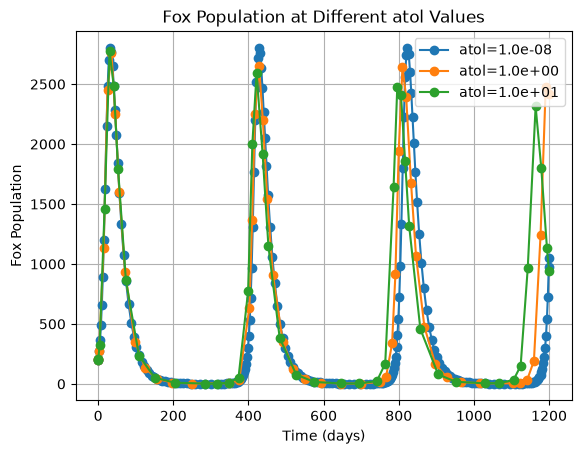

In [128]:
t_span = (0, 1200)
fox_peak.direction = -1

sol = solve_ivp(dydt, t_span, y0, rtol=1e-10, atol=1e-10, dense_output=True)
t_eval = np.linspace(0, 1200, 10000)
R_eval, F_eval = sol.sol(t_eval)

R_min = np.argmin(R_eval)
F_min = np.argmin(F_eval)
print(f"Minimum Rabbits: {R_eval[R_min]:.2f} at t = {t_eval[R_min]:.2f}")
print(f"Minimum Foxes: {F_eval[F_min]:.2f} at t = {t_eval[F_min]:.2f}")


for atol in (1e-8, 1.0, 10.0):
    sol = solve_ivp(dydt, t_span, y0, events=fox_peak, rtol=1e-06, atol=atol)
    F_peaks = sol.y_events[0][:, 1]
    print(
        f"atol = {atol:.1e},   fox peaks: {len(F_peaks)}, "
        f"first peak: {F_peaks[0]:.2f}, last peak: {F_peaks[-1]:.2f}, "
        f"drift: {F_peaks[-1] - F_peaks[0]:.2f}, nfev: {sol.nfev}"
    )
    plt.plot(sol.t, sol.y[1], "o-", label=f"atol={atol:.1e}")
plt.xlabel("Time (days)")
plt.ylabel("Fox Population")
plt.title("Fox Population at Different atol Values")
plt.legend()
plt.grid()
plt.show()


*Answer:*

The minimum number of rabbits are 7.43 at t = 887.25 days and minimum foxes are 1.59 at t = 297.63 days at least minimum absolute and relative tolerance. These fraction is meaning less while counting mammales. These can be roundup to the nearest values. 

At atol =1, the number of fox peaks are 4: more number of peaks compared to atol=1e-10. The peaks are same at atol =10 but drift is more negative compared to atol =1.

## 6. Which method?

At `rtol = 1e-8, atol = 1e-8`, compare `method=` `"RK45"`, `"DOP853"`, `"LSODA"`,
`"BDF"` and `"Radau"`: drift and `nfev` for each. Which is cheapest for this
problem? Is this problem stiff? How can you tell?

RK45      peaks= 3, drift = -3.741e-05 nfev =   3152
DOP853    peaks= 3, drift = -1.976e-06 nfev =   2063
Radau     peaks= 3, drift = 1.176e-07 nfev =  14273
BDF       peaks= 3, drift = -1.119e-03 nfev =   4675
LSODA     peaks= 3, drift = -3.505e-04 nfev =   1251


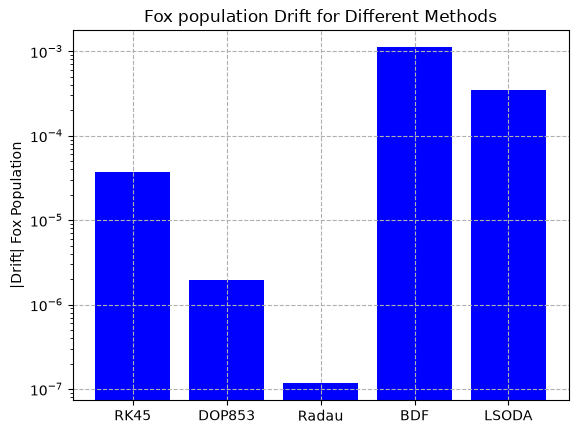

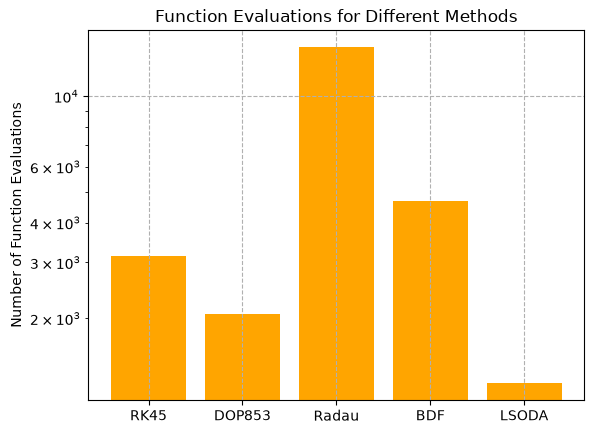

In [129]:
t_span = (0, 1200)

methods = ["RK45", "DOP853", "Radau", "BDF", "LSODA"]
drift = []
nfev = []

for method in methods:
    sol = solve_ivp(dydt, t_span, y0, events=fox_peak, method=method, rtol=1e-8, atol=1e-8)
    F_peaks = sol.y_events[0][:, 1]
    drift.append(F_peaks[-1] - F_peaks[0])
    nfev.append(sol.nfev)
    print(f"{method:8s}  peaks= {len(F_peaks)}, drift = {drift[-1]:.3e} "
    f"nfev = {sol.nfev:6d}")

drift = np.abs(drift)

plt.bar(methods, drift , color="blue")
plt.yscale("log")
plt.ylabel("|Drift| Fox Population")
plt.title("Fox population Drift for Different Methods")    
plt.grid(True, ls="--")
plt.show()


plt.bar(methods, nfev, color="orange")
plt.yscale("log")
plt.ylabel("Number of Function Evaluations")
plt.title("Function Evaluations for Different Methods")
plt.grid(True, ls="--")
plt.show()

*Answer:*

Compared to all methods, LSODA has lowest number of evaluation functions around 1e03 but drift values is very high(1e-045), whereas Radau has best drift value but it needs larger function evaluations which leads to high cost. BDF is least recommended among all methods because even with significant number of evaluations drift valu is too large(i.e 1e-03). DOP853 is cheapest and recommandel method, with fewer number of functional evalutions it gives better drift and next comes RK45. However, problem is not stiff even with two cheapest methds because these are explicit methods, these requires huge number of tiny tiny steps for convergance.  

## Stretch problems

**(a)** For this system the quantity
$V = k_3 R - k_4 \ln R + k_2 F - k_1 \ln F$ stays exactly constant. (Differentiate
it and substitute the two ODEs to check.) That's why the orbit is closed. Plot
how much $V$ changes over 1200 days for a few values of `rtol`. Is it a better
measure of the error than the peak drift?

**(b)** Re-run with $k_3 = 0.00004$ day$^{-1}$ rabbits$^{-1}$ for 800 days, as in
Lecture 3. The fixed point moves from (100, 375) to (1000, 375). Do your
conclusions about `rtol` change?

---

### When you're done

Restart & Run All. Check that every cell ran, in order, with no errors. Commit and
push. Then check on GitHub that your fork shows your latest commit, and that the
notebook displays with its plots.